In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm
# from tqdm.notebook import tqdm

from parallel_pandas import ParallelPandas
ParallelPandas.initialize(n_cpu=12)

from sklearn.preprocessing import StandardScaler, RobustScaler, PowerTransformer, QuantileTransformer, FunctionTransformer
from sklearn.cluster import BisectingKMeans
from sklearn.manifold import TSNE, trustworthiness
import umap
import hdbscan

import pickle
import os
import glob
import json

import warnings 
from IPython.display import display, HTML
warnings.filterwarnings("ignore")
plt.rcParams["patch.force_edgecolor"] = True

import veriwild_clustering as vwc

In [2]:
import kagglehub
dataset_path = kagglehub.dataset_download("markhomeless/intellivision-case")

In [3]:
# Список изображений
imglist = pd.read_csv(os.path.join(dataset_path, "IntelliVision_case", "images_paths.csv"))['paths']
imglist.head()

0    veriwild\1\00001\000001.jpg
1    veriwild\1\00001\000002.jpg
2    veriwild\1\00001\000003.jpg
3    veriwild\1\00001\000004.jpg
4    veriwild\1\00001\000005.jpg
Name: paths, dtype: str

In [4]:
# Папка с изображениями
imgpath = os.path.join(dataset_path, "IntelliVision_case", "raw_data")

# Размер поля для вывода 10 изображений в 2 ряда по 5 штук
FIGSIZE_IMG2X5 = (10, 5)

In [5]:
# Чтение очищенного датасета
with open(os.path.join('temp', 'vdc_color_cleaned.pickle'), 'rb') as pkl_file:
    vdc_color_cleaned = pickle.load(pkl_file)
    print(f'{"vdc_color_cleaned":<22}', vdc_color_cleaned.shape)

vdc_color_cleaned      (416314, 124)


# 3. Кластеризация

## 3.5. vdc_color, папйплайн по столбцам

### 2 кластера KMeans

In [6]:
%%time

vdc_color_pkmc2 = vwc.PipeKMeansCluster(
    pca_n_components=16, 
    n_clusters=2, 
    distorsion='Yeo-Johnson'
)
vdc_color_labels_kmeans2 = vdc_color_pkmc2.fit_predict(vdc_color_cleaned)

CPU times: total: 55.8 s
Wall time: 38.3 s


In [7]:
# Распределение кластеров
pd.concat([
    pd.Series(vdc_color_labels_kmeans2).value_counts(normalize=True),
    pd.Series(vdc_color_labels_kmeans2).value_counts(normalize=False)
], axis=1).sort_index()

,proportion,count
0,0.497444,207093
1,0.502556,209221


In [8]:
# 15 ближайших соседей к центроидам каждого кластера

_, vdc_color_indices_kmeans2 = vwc.get_kmeans_centroid_samples(
    data=vdc_color_pkmc2.X_pca,
    cluster_centers=vdc_color_pkmc2.kmeans.cluster_centers_,
    n_samples=15
)

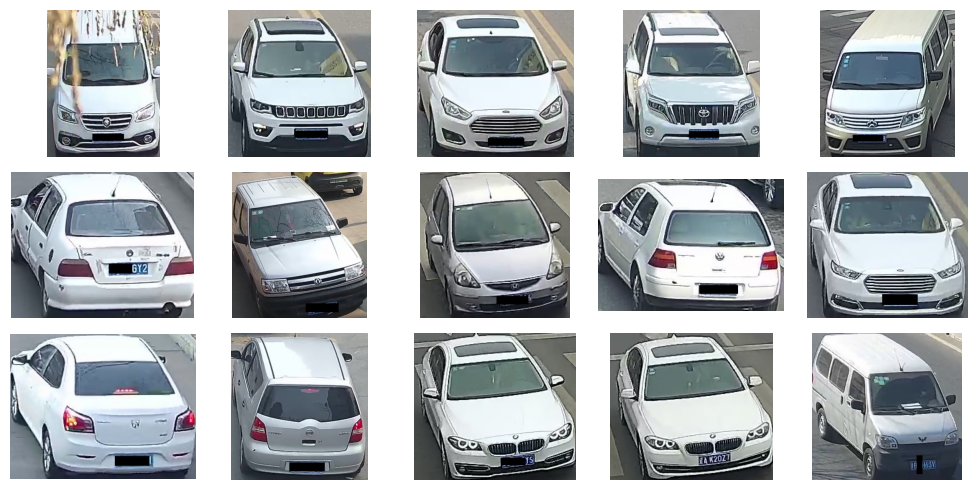

In [9]:
# Самые типичные представители класса 0 в vdc_color
vwc.draw_images(
    imgpath,
    imglist[vdc_color_indices_kmeans2[0]].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

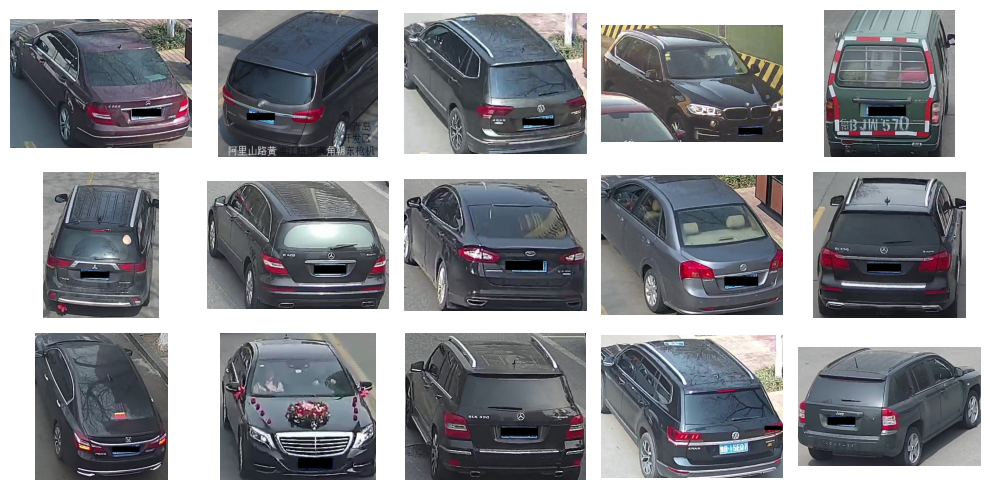

In [10]:
# Самые типичные представители класса 1 в vdc_color
vwc.draw_images(
    imgpath,
    imglist[vdc_color_indices_kmeans2[1]].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

In [11]:
# Быстрый тест на иерархичность:
# BisectingKMeans проверяет, делятся ли 2 макро-кластера на подкластеры

X_trans = vdc_color_pkmc2.X_pca

df_stab = []
for k in [2, 3, 4, 5, 6, 7, 8]:
    bkmeans = BisectingKMeans(n_clusters=k, random_state=42)
    labels = bkmeans.fit_predict(X_trans)
    # Стабильность для каждого K
    stability = vwc.cluster_stability(X_trans, n_clusters=k)
    print(f"Bisecting K={k}: Stability mean={stability['stability_mean']:.3f}, std={stability['stability_std']:.3f}")
    df_stab.append({'k': k, 'mean':stability['stability_mean'], 'std': stability['stability_std']})

df_stab = pd.DataFrame(df_stab)

Bisecting K=2: Stability mean=0.957, std=0.029
Bisecting K=3: Stability mean=0.517, std=0.120
Bisecting K=4: Stability mean=0.653, std=0.166
Bisecting K=5: Stability mean=0.559, std=0.097
Bisecting K=6: Stability mean=0.510, std=0.039
Bisecting K=7: Stability mean=0.474, std=0.050
Bisecting K=8: Stability mean=0.521, std=0.120


Тест на иерархичность показывает устойчивые варианты на 4 или 5 кластеров. Потенциально они гораздо интереснее, чем 2 больших кластера, где группировка произошла на светлые и темные оттенки.

### 4 кластера KMeans

Группировка на красные, светлые и темные оттенки. Светлые находятся в двух кластерах: преимущественно белые и преимущественно серебристые.

In [12]:
vdc_color_pkmc4 = vwc.PipeKMeansCluster(
    pca_n_components=16, 
    n_clusters=4,
    distorsion='RobustScaler'
)
vdc_color_labels_kmeans4 = vdc_color_pkmc4.fit_predict(vdc_color_cleaned)

In [13]:
# Распределение кластеров
pd.concat([
    pd.Series(vdc_color_labels_kmeans4).value_counts(normalize=True),
    pd.Series(vdc_color_labels_kmeans4).value_counts(normalize=False)
], axis=1).sort_index()

,proportion,count
0,0.247525,103048
1,0.395178,164518
2,0.301719,125610
3,0.055578,23138


In [14]:
# 15 ближайших соседей к центроидам каждого кластера

_, vdc_color_indices_kmeans4 = vwc.get_kmeans_centroid_samples(
    data=vdc_color_pkmc4.X_pca,
    cluster_centers=vdc_color_pkmc4.kmeans.cluster_centers_,
    n_samples=15
)

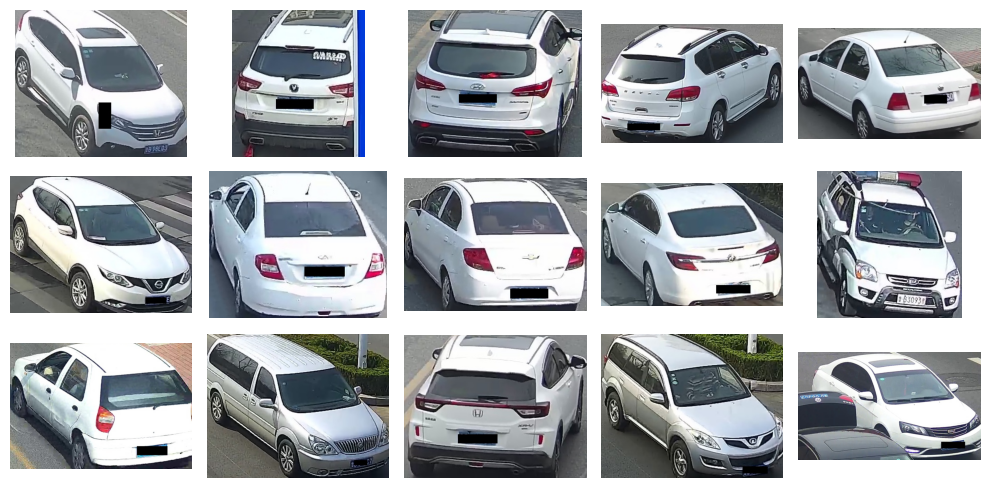

In [15]:
# Самые типичные представители класса 0 в vdc_color
vwc.draw_images(
    imgpath,
    imglist[vdc_color_indices_kmeans4[0]].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

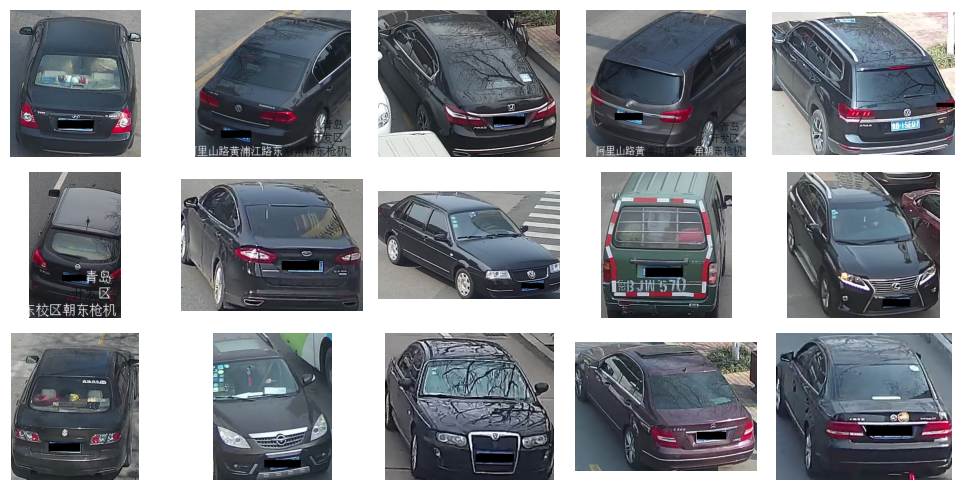

In [16]:
# Самые типичные представители класса 1 в vdc_color
vwc.draw_images(
    imgpath,
    imglist[vdc_color_indices_kmeans4[1]].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

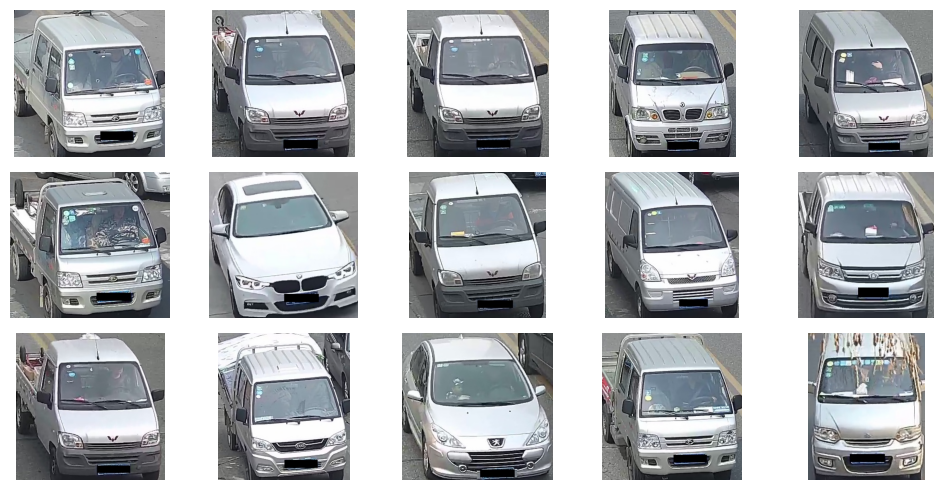

In [17]:
# Самые типичные представители класса 2 в vdc_color
vwc.draw_images(
    imgpath,
    imglist[vdc_color_indices_kmeans4[2]].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

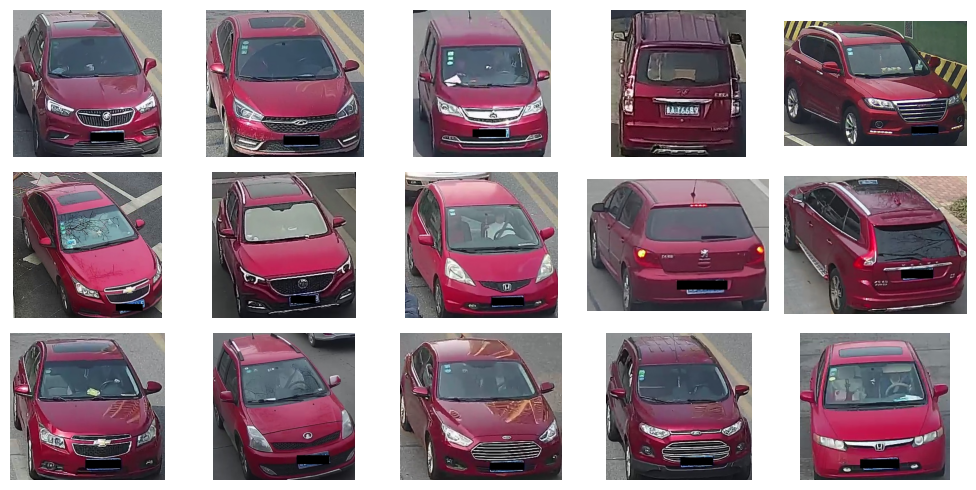

In [18]:
# Самые типичные представители класса 3 в vdc_color
vwc.draw_images(
    imgpath,
    imglist[vdc_color_indices_kmeans4[3]].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

### 3 кластера KMeans

Более лаконичный вариант предыдущей кластеризации. Белый (светлый), черный (темный) и красный цвета. Они являются самыми массовыми, но при этом полностью поглотили все остальные редкие оттенки.

In [19]:
vdc_color_pkmc3 = vwc.PipeKMeansCluster(
    pca_n_components=16, 
    n_clusters=3,
    distorsion='Yeo-Johnson'
)
vdc_color_labels_kmeans3 = vdc_color_pkmc3.fit_predict(vdc_color_cleaned)

In [20]:
# Распределение кластеров
pd.concat([
    pd.Series(vdc_color_labels_kmeans3).value_counts(normalize=True),
    pd.Series(vdc_color_labels_kmeans3).value_counts(normalize=False)
], axis=1).sort_index()

,proportion,count
0,0.488540,203386
1,0.450122,187392
2,0.061338,25536


In [21]:
# 15 ближайших соседей к центроидам каждого кластера

_, vdc_color_indices_kmeans3 = vwc.get_kmeans_centroid_samples(
    data=vdc_color_pkmc3.X_pca,
    cluster_centers=vdc_color_pkmc3.kmeans.cluster_centers_,
    n_samples=15
)

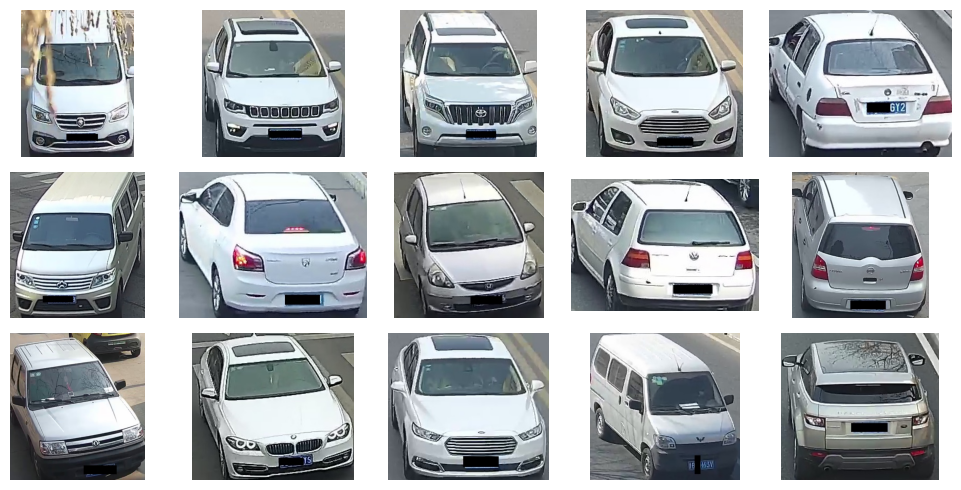

In [22]:
# Самые типичные представители класса 0 в vdc_color
vwc.draw_images(
    imgpath,
    imglist[vdc_color_indices_kmeans3[0]].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

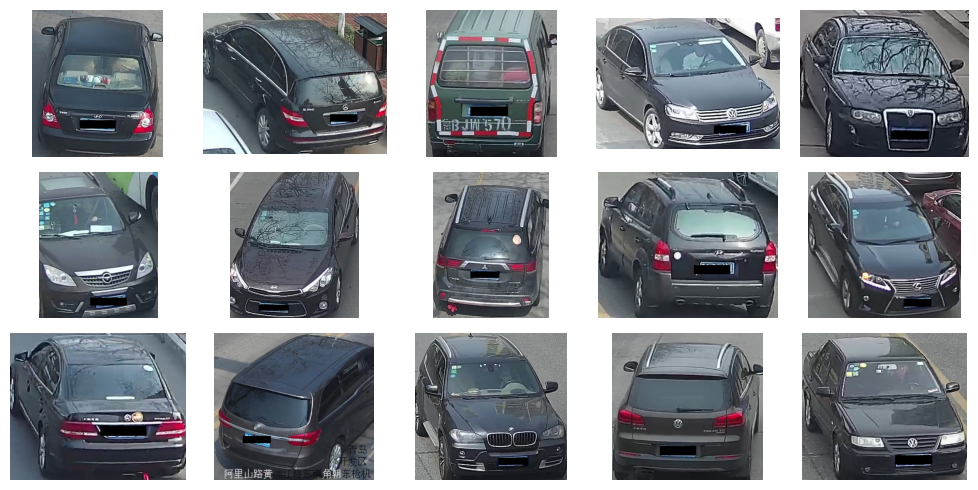

In [23]:
# Самые типичные представители класса 1 в vdc_color
vwc.draw_images(
    imgpath,
    imglist[vdc_color_indices_kmeans3[1]].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

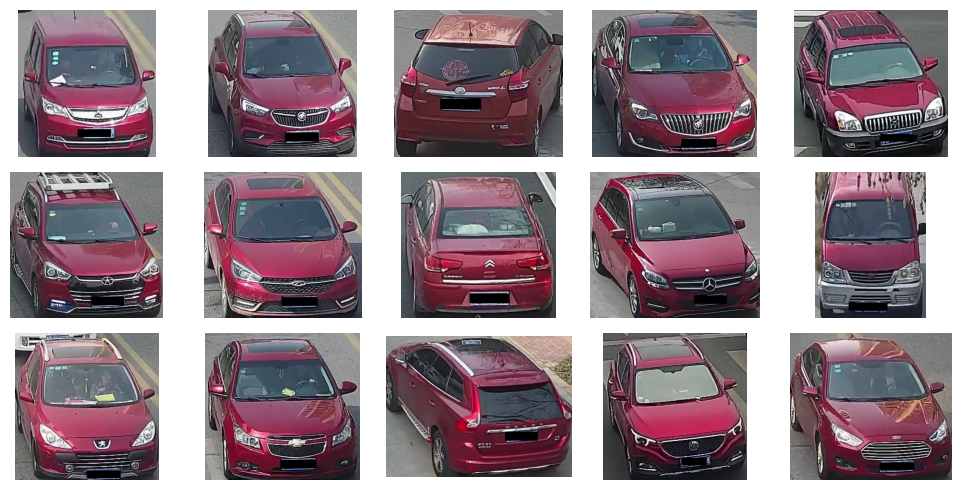

In [24]:
# Самые типичные представители класса 2 в vdc_color
vwc.draw_images(
    imgpath,
    imglist[vdc_color_indices_kmeans3[2]].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

### UMAP/HDBSCAN на 3 кластера

Наиболее интересный вариант для KMeans был на 3 кластера. Используем этот датасет с пониженной размерностью после PCA.

In [25]:
# После PCA размерность равна 16
X_trans = vdc_color_pkmc3.X_pca

# Подвыборка 25% для калибровки (100 тыс. автомобилей)
calibration_factor = 0.25

In [26]:
%%time 

umap_n_neighbors = 50 # Увеличено для макро-кластеров
umap_dims = [3, 5, 8, 10, 15]
eps_values = [0.0, 0.1, 0.3, 0.5, 0.8, 1.0]
min_samples_values = [2, 5, 10, 25, 50, 100, 250, 500]

df_umap = vwc.umap_hdbscan_measure(
    X_trans,
    sample_frac=calibration_factor,
    umap_n_components=umap_dims,
    umap_n_neighbors=umap_n_neighbors,  
    umap_metric='euclidean',
    cluster_selection_epsilon=eps_values,
    min_samples=min_samples_values,
    ram_factor=0.7,
    n_jobs=10
)

Используется выборка: 416314 -> 104078 строк (25.0%)
Для trustworthiness выборка уменьшена: 104078 -> 70063 строк (67.3%)


umap_dim: 100%|██████████| 5/5 [1:18:40<00:00, 944.02s/it]

CPU times: total: 1h 9min 13s
Wall time: 1h 18min 40s


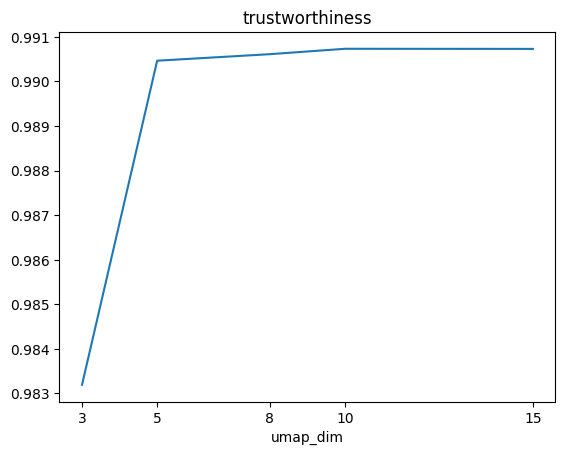

In [27]:
# trustworthiness выходит на плато начиная с umap_dim=8
g_umap_dim = df_umap.groupby('umap_dim', sort=True)['trustworthiness'].first()
ax = g_umap_dim.plot()
ax.set_xticks(g_umap_dim.index.to_list())
ax.set_title('trustworthiness');

In [28]:
# Минимальная доля шума наблюдается для umap_dim>=5
s_umap_dim = df_umap[df_umap['umap_dim']>=5]
noise_pct_rank = s_umap_dim.groupby(['eps', 'min_samples'])['noise_pct'].rank(method='dense', ascending=True)
s_umap_dim = s_umap_dim[noise_pct_rank==1]
noise_pct_rank = s_umap_dim['noise_pct'].rank(method='dense', ascending=True)

s_umap_dim[noise_pct_rank==1]

,eps,min_samples,umap_dim,trustworthiness,clusters_found,noise_pct,min_cluster_pct,min_cluster_cnt
1,0.0,2,5,0.990465,2,0.0,0.061444,6395
2,0.0,2,8,0.990612,2,0.0,0.061281,6378
3,0.0,2,10,0.990733,2,0.0,0.061387,6389
4,0.0,2,15,0.990730,2,0.0,0.061281,6378
6,0.0,5,5,0.990465,2,0.0,0.061444,6395
...,...,...,...,...,...,...,...,...
232,1.0,250,8,0.990612,2,0.0,0.061281,6378
233,1.0,250,10,0.990733,2,0.0,0.061387,6389
234,1.0,250,15,0.990730,2,0.0,0.061281,6378
236,1.0,500,5,0.990465,3,0.0,0.061444,6395


In [29]:
s_umap_dim[(noise_pct_rank==1) & (s_umap_dim['umap_dim']==5)]

,eps,min_samples,umap_dim,trustworthiness,clusters_found,noise_pct,min_cluster_pct,min_cluster_cnt
1,0.0,2,5,0.990465,2,0.0,0.061444,6395
6,0.0,5,5,0.990465,2,0.0,0.061444,6395
11,0.0,10,5,0.990465,2,0.0,0.061444,6395
16,0.0,25,5,0.990465,2,0.0,0.061444,6395
21,0.0,50,5,0.990465,2,0.0,0.061444,6395
26,0.0,100,5,0.990465,2,0.0,0.061444,6395
31,0.0,250,5,0.990465,2,0.0,0.061444,6395
36,0.0,500,5,0.990465,3,0.0,0.061444,6395
41,0.1,2,5,0.990465,2,0.0,0.061444,6395
46,0.1,5,5,0.990465,2,0.0,0.061444,6395


In [30]:
df_umap[(df_umap['umap_dim']==5) & (df_umap['clusters_found']>2)]

,eps,min_samples,umap_dim,trustworthiness,clusters_found,noise_pct,min_cluster_pct,min_cluster_cnt
36,0.0,500,5,0.990465,3,0.0,0.061444,6395
76,0.1,500,5,0.990465,3,0.0,0.061444,6395
116,0.3,500,5,0.990465,3,0.0,0.061444,6395
156,0.5,500,5,0.990465,3,0.0,0.061444,6395
196,0.8,500,5,0.990465,3,0.0,0.061444,6395
236,1.0,500,5,0.990465,3,0.0,0.061444,6395


In [ ]:
%%time

import umap
import hdbscan

umap_n_neighbors = 50

umap_dim = 5
eps_value = 0.1
min_samples_value = 250

# Коэффициент увеличения объема выборки
scale = 1.0 / calibration_factor

# UMAP: n_neighbors масштабируется через логарифм
n_neighbors_full = int(umap_n_neighbors * (1.0 + np.log2(scale)))

# 2. HDBSCAN: min_samples задает радиус ядерных точек (core distance). 
# Если плотность в выборке вырастает, то радиус должен уменьшиться.
min_samples_full = int(min_samples_value * (1.0 + np.log2(scale)))

# 3. HDBSCAN: epsilon сжимается обратно пропорционально линейной плотности в d-мерном пространстве UMAP
eps_full = eps_value * (calibration_factor ** (1.0 / umap_dim))

# 4. HDBSCAN: min_cluster_size необходимо сохранить в размере 2% данных, так как модель склонна создавать много маленьких кластеров 
min_cluster_size_full = max(1, int(X_trans.shape[0] * 0.02))

reducer = umap.UMAP(
    n_components=umap_dim, 
    n_neighbors=n_neighbors_full,    
    min_dist=0.0,       
    metric='euclidean', 
    n_jobs=10,
    random_state=42
)
X_umap = reducer.fit_transform(X_trans)

CPU times: total: 49min 41s
Wall time: 19min 2s


In [41]:
print(f'{scale=}, n_neighbors={n_neighbors_full}, min_samples={min_samples_full}, cluster_selection_epsilon={eps_full:.2f}, min_cluster_size={min_cluster_size_full}')

scale=4.0, n_neighbors=150, min_samples=750, cluster_selection_epsilon=0.08, min_cluster_size=8326


In [ ]:
%%time

hdb = hdbscan.HDBSCAN(
    min_cluster_size=min_cluster_size_full, 
    min_samples=min_samples_full,     
    cluster_selection_epsilon=eps_full,
    cluster_selection_method="eom",
    core_dist_n_jobs=4,
    prediction_data=True
)
vdc_color_labels_hdbscan = hdb.fit_predict(X_umap)

CPU times: total: 5min 53s
Wall time: 5min 55s


In [40]:
# Распределение кластеров
pd.concat([
    pd.Series(vdc_color_labels_hdbscan).value_counts(normalize=True),
    pd.Series(vdc_color_labels_hdbscan).value_counts(normalize=False)
], axis=1).sort_index()

,proportion,count
-1,0.000228,95
0,0.061473,25592
1,0.421439,175451
2,0.516860,215176


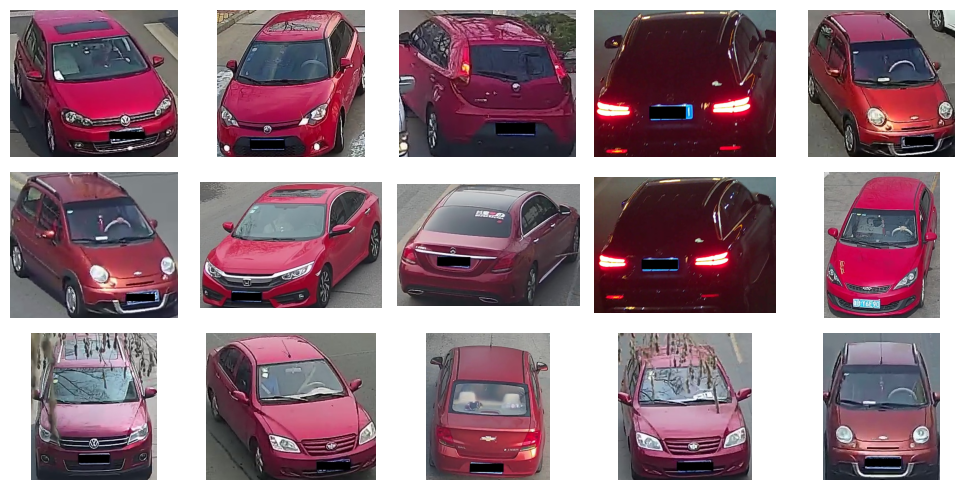

In [42]:
# 15 самых типичных представителей класса 0 в vdc_color

vdc_color_0_indices = vwc.get_hdbscan_best_cluster_samples(hdb, 0, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[vdc_color_0_indices].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

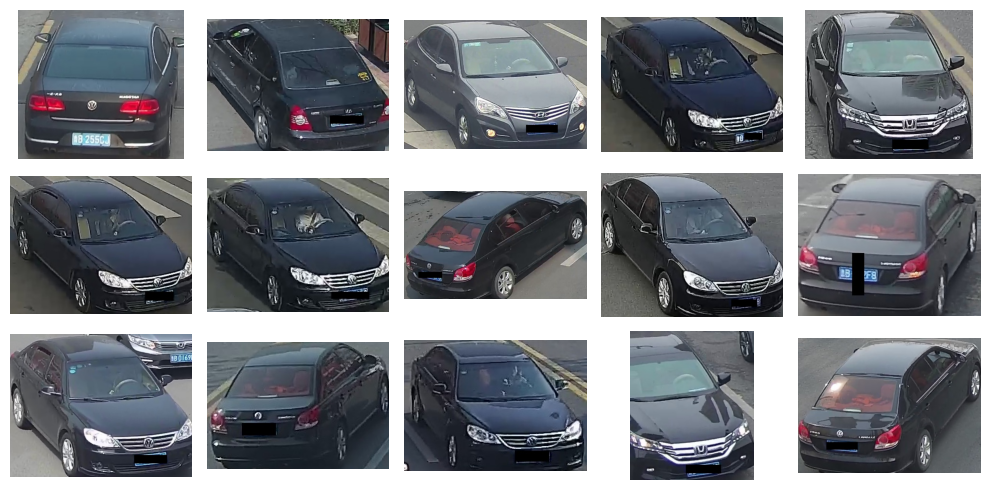

In [43]:
# 15 самых типичных представителей класса 1 в vdc_color

vdc_color_1_indices = vwc.get_hdbscan_best_cluster_samples(hdb, 1, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[vdc_color_1_indices].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

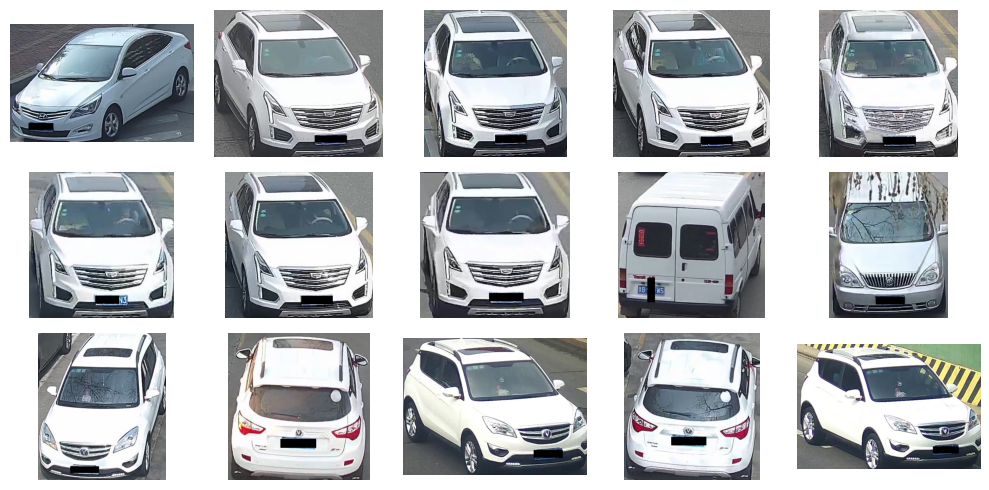

In [44]:
# 15 самых типичных представителей класса 2 в vdc_color

vdc_color_2_indices = vwc.get_hdbscan_best_cluster_samples(hdb, 2, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[vdc_color_2_indices].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

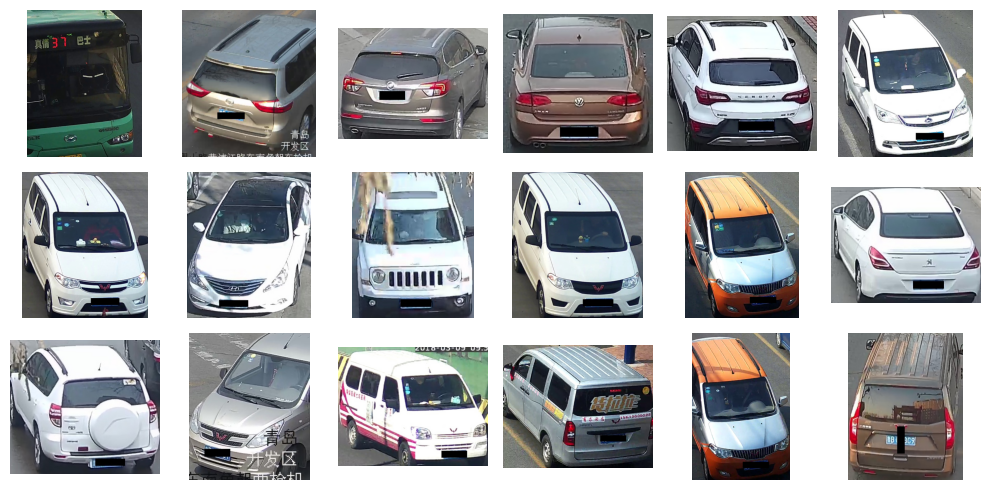

In [46]:
# 10 самых далеких выбросов в vdc_color
vdc_color_hdbscan_outliers = vwc.get_hdbscan_outliers_samples(hdb, 20)
vwc.draw_images(
    imgpath,
    imglist[vdc_color_hdbscan_outliers].to_list(), 
    nrows=3, ncols=6, figsize=FIGSIZE_IMG2X5
)

In [47]:
%%time

# t-SNE для визуализации

from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=42, n_jobs=12)
X_tsne = tsne.fit_transform(X_umap)

CPU times: total: 2h 42min 15s
Wall time: 19min 4s


In [48]:
vdc_color_visual2_tsne = pd.DataFrame(
    np.hstack([
        X_tsne, 
        vdc_color_labels_hdbscan.reshape(-1, 1),
        vdc_color_labels_kmeans3.reshape(-1, 1)
    ]), 
    columns=['x', 'y', 'cluster_hdbscan', 'cluster_kmeans']
)
vdc_color_visual2_tsne['cluster_hdbscan'] = vdc_color_visual2_tsne['cluster_hdbscan'].astype(np.int8)
vdc_color_visual2_tsne['cluster_kmeans'] = vdc_color_visual2_tsne['cluster_kmeans'].astype(np.int8)

In [49]:
# Перевод меток KMeans в систему координат HDBSCAN
mapping = vwc.match_labels(
    vdc_color_visual2_tsne['cluster_hdbscan'].to_numpy(),
    vdc_color_visual2_tsne['cluster_kmeans'].to_numpy()
)
vdc_color_visual2_tsne['cluster_kmeans_aligned'] = vdc_color_visual2_tsne['cluster_kmeans'].map(mapping)

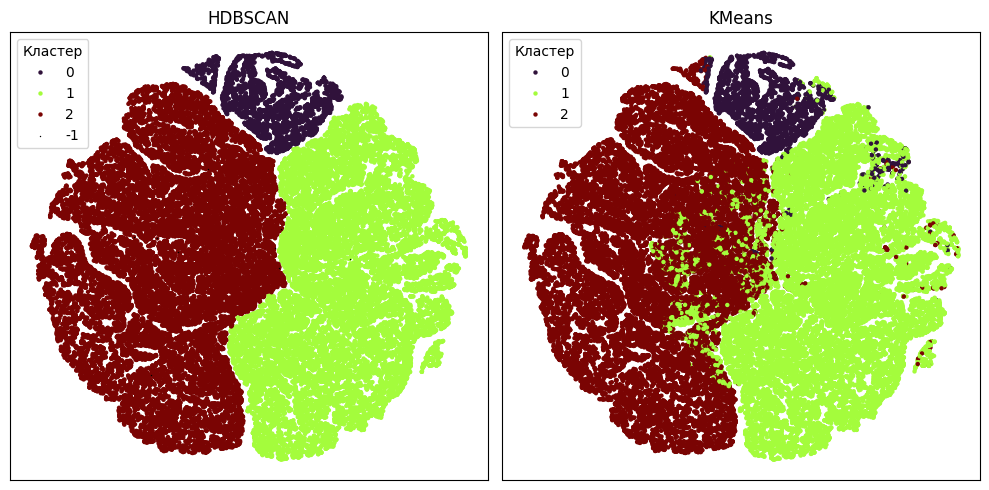

In [50]:
vwc.show_2d_spaces(
    vdc_color_visual2_tsne, 
    'cluster_hdbscan', 'cluster_kmeans_aligned',
    frac=0.1, palette='turbo'
)

Алгоритм HDBSCAN после перебора параметров смог найти не более трех кластеров, которые очень похожи на результат KMeans. Довольно грубое разбиение, зато честное и стабильное. В следовых количествах обнаружены выбросы, состоящие из двухцветных автомобилей, с надписями на борту и несколько других с неочевидными признаками.

In [ ]:
# Сохранение меток
vdc_color_visual2_tsne[['cluster_hdbscan', 'cluster_kmeans_aligned']].to_csv(
    os.path.join('temp', 'vdc_color_colspipeline_labels.csv'), 
    index=False
)

## 3.6. vdc_color, папйплайн по строкам

### 2 кластера KMeans

In [25]:
%%time

vdc_color_pkmc_l2 = vwc.PipeKMeansClusterL2(
    pca_n_components=5, 
    n_clusters=2
)
vdc_color_labels_l2_kmeans = vdc_color_pkmc_l2.fit_predict(vdc_color_cleaned)

CPU times: total: 12.1 s
Wall time: 1.87 s


In [26]:
# Распределение кластеров
pd.concat([
    pd.Series(vdc_color_labels_l2_kmeans).value_counts(normalize=True),
    pd.Series(vdc_color_labels_l2_kmeans).value_counts(normalize=False)
], axis=1).sort_index()

,proportion,count
0,0.51313,213623
1,0.48687,202691


KMeans лучше всего делит данные на белые (светлые) и черные (темные) оттенки. Это слишком грубое разбиение. Быстрый тест на иерархичность не находит преимуществ у других вариантов разбиений.

In [27]:
# 15 ближайших соседей к центроидам каждого кластера

_, vdc_color_indices_kmeans_l2 = vwc.get_kmeans_centroid_samples(
    data=vdc_color_pkmc_l2.X_pca,
    cluster_centers=vdc_color_pkmc_l2.kmeans.cluster_centers_,
    n_samples=15
)

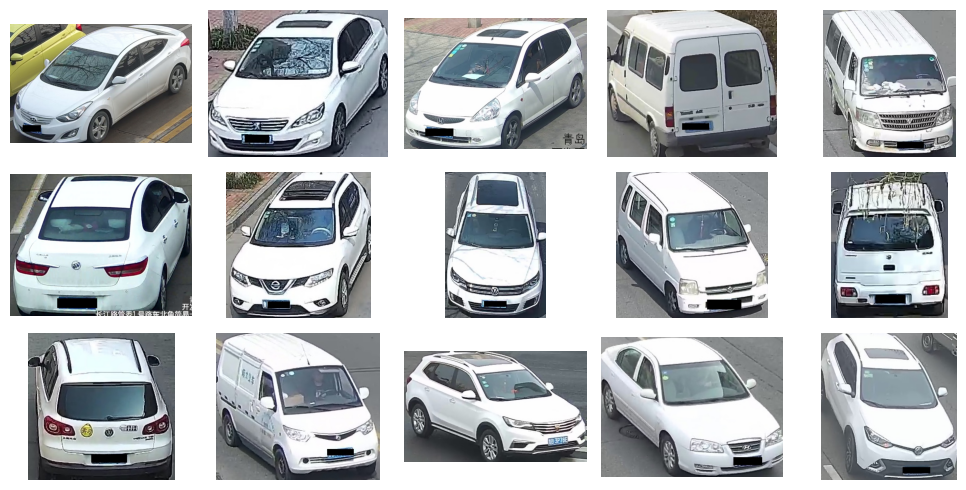

In [28]:
# Самые типичные представители класса 0 в vdc_color
vwc.draw_images(
    imgpath,
    imglist[vdc_color_indices_kmeans_l2[0]].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

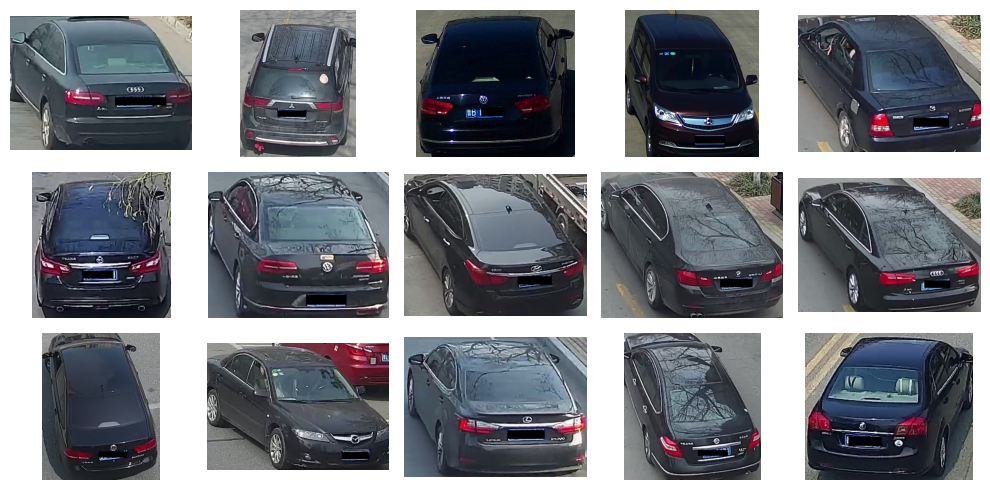

In [29]:
# Самые типичные представители класса 1 в vdc_color
vwc.draw_images(
    imgpath,
    imglist[vdc_color_indices_kmeans_l2[1]].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

In [30]:
# Быстрый тест на иерархичность:
# BisectingKMeans проверяет, делятся ли 2 макро-кластера на подкластеры

X_trans = vdc_color_pkmc_l2.X_pca

df_stab = []
for k in [2, 3, 4, 5, 6, 7, 8]:
    bkmeans = BisectingKMeans(n_clusters=k, random_state=42)
    labels = bkmeans.fit_predict(X_trans)
    # Стабильность для каждого K
    stability = vwc.cluster_stability(X_trans, n_clusters=k)
    print(f"Bisecting K={k}: Stability mean={stability['stability_mean']:.3f}, std={stability['stability_std']:.3f}")
    df_stab.append({'k': k, 'mean':stability['stability_mean'], 'std': stability['stability_std']})

df_stab = pd.DataFrame(df_stab)

Bisecting K=2: Stability mean=0.998, std=0.001
Bisecting K=3: Stability mean=0.738, std=0.203
Bisecting K=4: Stability mean=0.726, std=0.134
Bisecting K=5: Stability mean=0.606, std=0.161
Bisecting K=6: Stability mean=0.618, std=0.153
Bisecting K=7: Stability mean=0.637, std=0.052
Bisecting K=8: Stability mean=0.592, std=0.079


Для алгоритмов семейства KMeans самая высокая стабильность наблюдается при разделении на 2 кластера, но реальной пользы от такого разбиения недостаточно. Трехкластерный вариант выделяет красные автомобили. Хотя проверка на иерархичность показывает еще потенциально интересный "островок стабильности" для решения с 7 кластерами, но в реальности для 4 кластеров и выше группировка происходит уже не только по цветам, но и по ракурсу изображения, что фактически повторяет результаты кластеризации дескрипторов osnet.

### UMAP/HDBSCAN на 2 кластера

In [31]:
# После PCA размерность равна 5
X_trans = vdc_color_pkmc_l2.X_pca

# Подвыборка 25% для калибровки (100 тыс. автомобилей)
calibration_factor = 0.25

In [32]:
%%time 

umap_n_neighbors = 50 # Увеличено для макро-кластеров
umap_dims = [2, 3, 4, 5]
eps_values = [0.0, 0.1, 0.3, 0.5, 0.8, 1.0]
min_samples_values = [2, 5, 10, 25, 50, 100, 250, 500, 1000]

df_umap = vwc.umap_hdbscan_measure(
    X_trans,
    sample_frac=calibration_factor,
    umap_n_components=umap_dims,
    umap_n_neighbors=umap_n_neighbors,  
    umap_metric='cosine',
    cluster_selection_epsilon=eps_values,
    min_samples=min_samples_values,
    ram_factor=0.7,
    n_jobs=10
)

Используется выборка: 416314 -> 104078 строк (25.0%)
Для trustworthiness выборка уменьшена: 104078 -> 72074 строк (69.2%)


umap_dim: 100%|██████████| 4/4 [1:10:24<00:00, 1056.24s/it]

CPU times: total: 58min 10s
Wall time: 1h 10min 25s


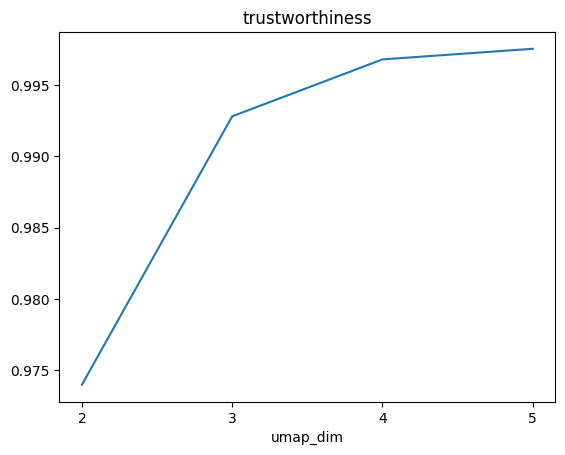

In [33]:
# trustworthiness на плато не выходит. Размерность 5 (как у PCA) будет оптимальной
g_umap_dim = df_umap.groupby('umap_dim', sort=True)['trustworthiness'].first()
ax = g_umap_dim.plot()
ax.set_xticks(g_umap_dim.index.to_list())
ax.set_title('trustworthiness');

In [34]:
# Минимальная доля шума при dim=5
s_umap_dim = df_umap[df_umap['umap_dim']==5]
noise_pct_rank = s_umap_dim.groupby(['eps', 'min_samples'])['noise_pct'].rank(method='dense', ascending=True)
s_umap_dim = s_umap_dim[noise_pct_rank==1]
noise_pct_rank = s_umap_dim['noise_pct'].rank(method='dense', ascending=True)

s_umap_dim[noise_pct_rank==1]

,eps,min_samples,umap_dim,trustworthiness,clusters_found,noise_pct,min_cluster_pct,min_cluster_cnt
35,0.0,1000,5,0.997554,2,0.0,0.496041,51627
71,0.1,1000,5,0.997554,2,0.0,0.496041,51627
107,0.3,1000,5,0.997554,2,0.0,0.496041,51627
143,0.5,1000,5,0.997554,2,0.0,0.496041,51627
179,0.8,1000,5,0.997554,2,0.0,0.496041,51627
215,1.0,1000,5,0.997554,2,0.0,0.496041,51627


In [35]:
df_umap['clusters_found'].value_counts().sort_index()

clusters_found
2    170
3     10
4      5
5     12
6      7
7      6
8      2
9      4
Name: count, dtype: int64

Показатель trustworthiness на плато не выходит, но значения 0.99 и выше говорят, что геометрия соседства сохраняется идеально. Размерность 5, как у PCA, получается оптимальной. Калибровка происходила на выборке 25% от всех данных, но воспроизвести этот результат на полном датасете крайне затруднительно. 

In [94]:
%%time

import umap
import hdbscan

umap_dim = 5
eps_value = 0.1
# min_samples_value = 1000

# Коэффициент увеличения объема выборки
scale = 1.0 / calibration_factor

# UMAP: n_neighbors масштабируется через логарифм
# n_neighbors_full = int(umap_n_neighbors * (1.0 + np.log2(scale)))
n_neighbors_full = 200

# 2. HDBSCAN: min_samples задает радиус ядерных точек (core distance). 
# Если плотность в выборке вырастает, то радиус должен уменьшиться.
# min_samples_full = int(min_samples_value * (1.0 + np.log2(scale)))
min_samples_full = 4000

# 3. HDBSCAN: epsilon сжимается обратно пропорционально линейной плотности в d-мерном пространстве UMAP
eps_full = eps_value * (calibration_factor ** (1.0 / umap_dim))

# 4. HDBSCAN: min_cluster_size необходимо сохранить в размере 2% данных, так как модель склонна создавать много маленьких кластеров 
min_cluster_size_full = max(1, int(X_trans.shape[0] * 0.02))

print(f'{scale=}, n_neighbors={n_neighbors_full}, min_samples={min_samples_full}, cluster_selection_epsilon={eps_full:.2f}, min_cluster_size={min_cluster_size_full}')

# Этап UMAP остается несмотря на выбор такой же размерности, как у PCA. 
# UMAP меняет геометрию пространства, чем пользуется HDBSCAN.
reducer = umap.UMAP(
    n_components=umap_dim, 
    n_neighbors=n_neighbors_full,    
    min_dist=0.0,       
    metric='cosine', 
    n_jobs=12,
    random_state=42
)
X_umap = reducer.fit_transform(X_trans)

scale=4.0, n_neighbors=200, min_samples=4000, cluster_selection_epsilon=0.08, min_cluster_size=8326
CPU times: total: 48min 33s
Wall time: 18min 27s


In [95]:
%%time

hdb = hdbscan.HDBSCAN(
    min_cluster_size=min_cluster_size_full, 
    min_samples=min_samples_full,     
    cluster_selection_epsilon=eps_full,
    cluster_selection_method="eom",
    core_dist_n_jobs=1,
    prediction_data=True
)
vdc_color_labels_l2_hdbscan = hdb.fit_predict(X_umap)

CPU times: total: 15min 45s
Wall time: 17min 2s


In [96]:
# Распределение кластеров
pd.concat([
    pd.Series(vdc_color_labels_l2_hdbscan).value_counts(normalize=True),
    pd.Series(vdc_color_labels_l2_hdbscan).value_counts(normalize=False)
], axis=1).sort_index()

,proportion,count
-1,0.156118,64994
0,0.435316,181228
1,0.063632,26491
2,0.344934,143601


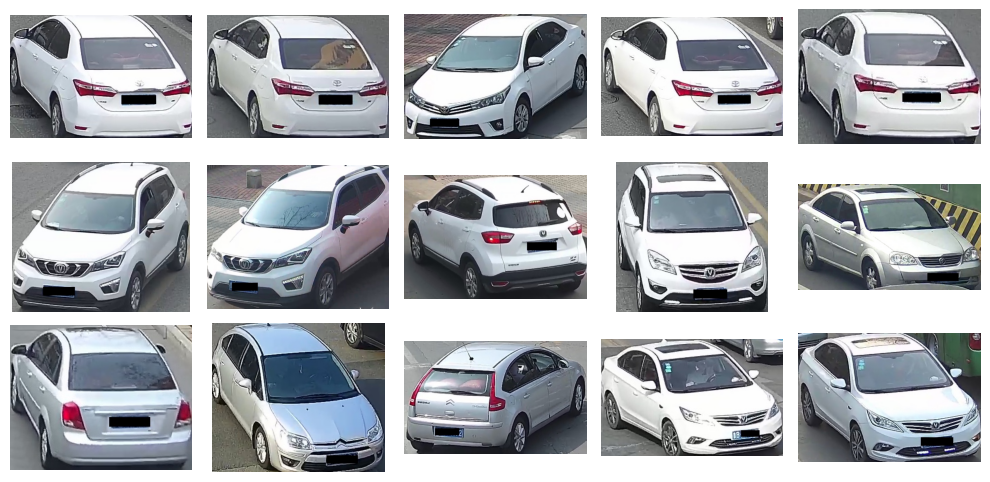

In [97]:
# 15 самых типичных представителей класса 0 в vdc_color

vdc_color_0_indices_l2 = vwc.get_hdbscan_best_cluster_samples(hdb, 0, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[vdc_color_0_indices_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

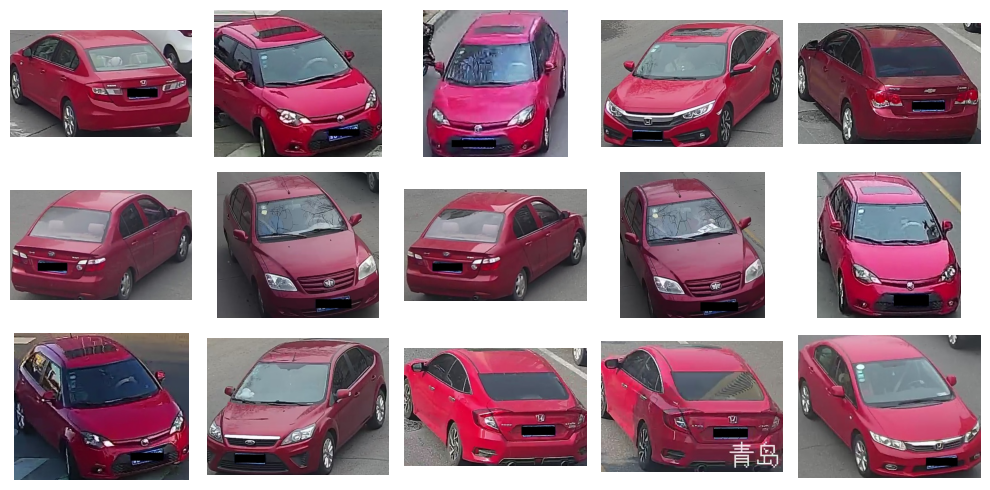

In [98]:
# Самые типичные представители класса 1 в vdc_color

vdc_color_1_indices_l2 = vwc.get_hdbscan_best_cluster_samples(hdb, 1, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[vdc_color_1_indices_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

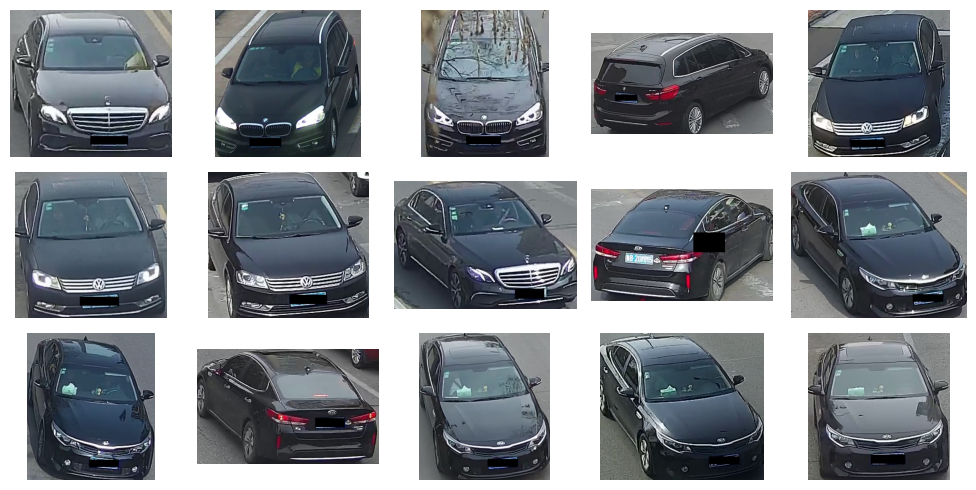

In [99]:
# 15 самых типичных представителей класса 2 в vdc_color

vdc_color_2_indices_l2 = vwc.get_hdbscan_best_cluster_samples(hdb, 2, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[vdc_color_2_indices_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

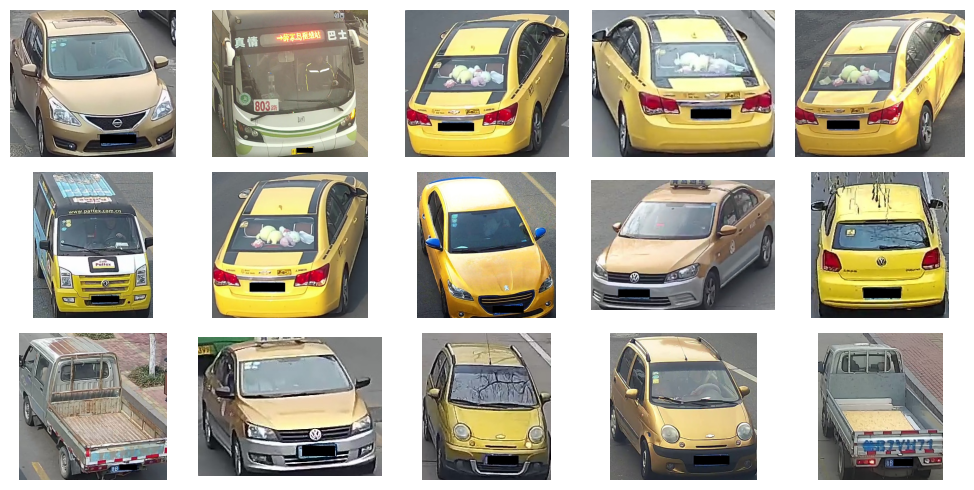

In [100]:
# Самые далекие выбросы в vdc_color
vdc_color_hdbscan_outliers_l2 = vwc.get_hdbscan_outliers_samples(hdb, 15)
vwc.draw_images(
    imgpath,
    imglist[vdc_color_hdbscan_outliers_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

Алгоритм HDBSCAN выделил светлые машины (44%, кластер 0), красные (6%, кластер 1) и темные (34%, кластер 2). Самыми дальними выбросами оказались машины различных оттенков желтого. Такой результат гораздо лучше, чем у KMeans с его 2 кластерами светлых и темных оттенков. Визуализация с помощью t-SNE показала схожесть результатов HDBSCAN и KMeans. Для быстрого разделения на 3 кластера можно использовать KMeans, но HDBSCAN интересен тем, что остальные цвета (около 16% данных), которые он отнес к шуму, можно рассматривать как еще один кластер.

In [101]:
%%time

# t-SNE для визуализации

from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=42, n_jobs=12)
X_tsne = tsne.fit_transform(X_umap)

CPU times: total: 2h 42min 24s
Wall time: 20min 6s


In [102]:
vdc_color_visual2_tsne_l2 = pd.DataFrame(
    np.hstack([
        X_tsne, 
        vdc_color_labels_l2_hdbscan.reshape(-1, 1),
        vdc_color_labels_l2_kmeans.reshape(-1, 1)
    ]), 
    columns=['x', 'y', 'cluster_hdbscan', 'cluster_kmeans']
)
vdc_color_visual2_tsne_l2['cluster_hdbscan'] = vdc_color_visual2_tsne_l2['cluster_hdbscan'].astype(np.int8)
vdc_color_visual2_tsne_l2['cluster_kmeans'] = vdc_color_visual2_tsne_l2['cluster_kmeans'].astype(np.int8)

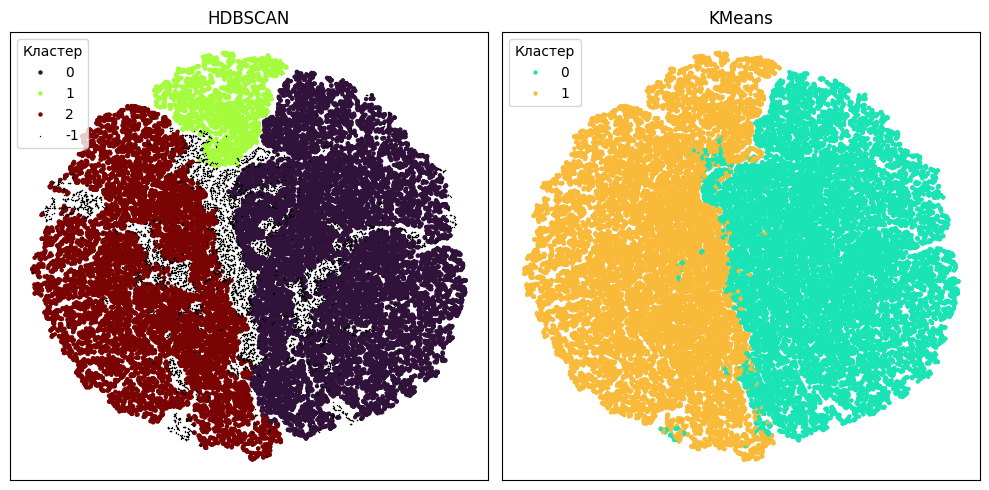

In [103]:
vwc.show_2d_spaces(
    vdc_color_visual2_tsne_l2, 
    'cluster_hdbscan', 'cluster_kmeans',
    frac=0.1, palette='turbo'
)

In [63]:
# Сохранение меток
vdc_color_visual2_tsne_l2[['cluster_hdbscan', 'cluster_kmeans_aligned']].to_csv(
    os.path.join('temp', 'vdc_color_rowspipeline_labels.csv'), 
    index=False
)